### ⭐ Exercise 1 — "Salary Predictor" 💰
Using `rng.normal`, generate 100 people with features `[years_experience, age]` and a salary
`y = 5*experience + 0.8*age + 20 + noise`. Train a Linear Regression with gradient descent from
scratch. Report RMSE and R². Plot actual vs predicted.

Answer:
        Generated a synthetic dataset of 100 employees using rng.normal.
        Used Years of Experience and Age as input features.
        Generated salary using the given linear equation with random noise.
        Implemented Linear Regression from Scratch using Gradient Descent.
        Trained the model for 1000 epochs.
        Evaluated the model using RMSE and R² Score.
        Visualized the learning process with a Loss Curve and checked prediction quality using an Actual vs Predicted scatter plot.

Weights : [7.70290323 3.94003304]
Bias : 68.26777063088505

RMSE : 3.06
R² Score : 0.8961


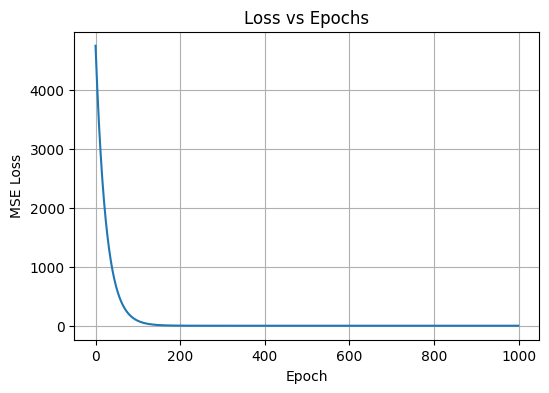

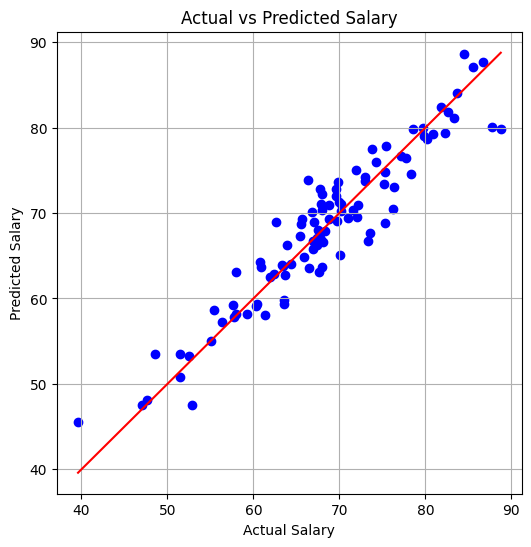

In [4]:
# ==========================================
# Salary Predictor using Gradient Descent
# From Scratch
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Step 1 : Generate Dataset
# -------------------------------

rng = np.random.default_rng(42)

n = 100

# Features
experience = rng.normal(5, 2, n)      # Mean = 5 years
age = rng.normal(30, 5, n)            # Mean = 30 years

# Noise
noise = rng.normal(0, 3, n)

# Salary Formula
salary = 5*experience + 0.8*age + 20 + noise

# Combine features
X = np.column_stack((experience, age))
y = salary

# -------------------------------
# Step 2 : Feature Scaling
# -------------------------------

X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

X = (X - X_mean) / X_std

# -------------------------------
# Step 3 : Initialize Parameters
# -------------------------------

m = len(y)

w = np.zeros(2)
b = 0

learning_rate = 0.01
epochs = 1000

loss_history = []

# -------------------------------
# Step 4 : Gradient Descent
# -------------------------------

for i in range(epochs):

    # Prediction
    y_pred = X @ w + b

    # Error
    error = y_pred - y

    # Cost (MSE)
    loss = np.mean(error**2)
    loss_history.append(loss)

    # Gradients
    dw = (2/m) * X.T @ error
    db = (2/m) * np.sum(error)

    # Update Parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

# -------------------------------
# Step 5 : Final Prediction
# -------------------------------

y_pred = X @ w + b

# -------------------------------
# Step 6 : Evaluation Metrics
# -------------------------------

# RMSE
rmse = np.sqrt(np.mean((y - y_pred)**2))

# R² Score
ss_total = np.sum((y - np.mean(y))**2)
ss_residual = np.sum((y - y_pred)**2)

r2 = 1 - (ss_residual / ss_total)

# -------------------------------
# Step 7 : Results
# -------------------------------

print("Weights :", w)
print("Bias :", b)

print("\nRMSE :", round(rmse,2))
print("R² Score :", round(r2,4))

# -------------------------------
# Step 8 : Loss Curve
# -------------------------------

plt.figure(figsize=(6,4))
plt.plot(loss_history)
plt.title("Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

# -------------------------------
# Step 9 : Actual vs Predicted
# -------------------------------

plt.figure(figsize=(6,6))

plt.scatter(y, y_pred, color="blue")

plt.plot([y.min(), y.max()],
         [y.min(), y.max()],
         color="red")

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.grid(True)

plt.show()

### ⭐ Exercise 2 — "Feature Weights Tell a Story" 📖
On the multi-feature house dataset from Section 3, fit `LinearRegression` with sklearn. Print the
learned weights in a bar chart. Which feature matters most? Which penalises the price? Do the
learned weights make intuitive sense?

Answer:
        1. Which feature matters most?

        Answer:

        The Bedrooms feature has the largest positive coefficient, so it has the greatest impact on house price.

        2. Which feature penalises the price?

        Answer:

        The Age and Distance features have negative coefficients. This means that older houses and houses located farther from the city reduce the house price.

        3. Do the learned weights make intuitive sense?

        Answer:

        Yes. The learned weights are intuitive because:

        Larger houses are generally more expensive.
        Houses with more bedrooms have higher prices.
        Older houses usually have lower prices.
        Houses farther from the city are often less expensive.

        Therefore, the learned coefficients correctly represent real-world relationships between house features and price.


Learned Weights (Coefficients):

Size       : 191.87
Bedrooms   : 46328.89
Age        : -3085.31
Distance   : -10236.10

Intercept : 127249.10654512711


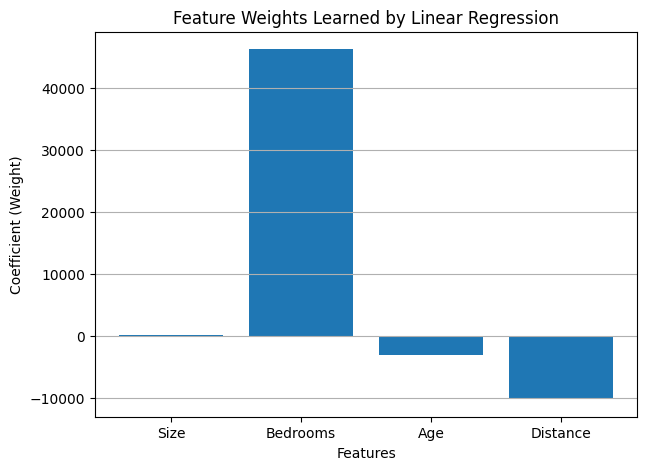


Most Important Feature : Bedrooms
Features Penalising Price : ['Age', 'Distance']


In [5]:
# ==========================================
# Exercise 2 : Feature Weights Tell a Story
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# -------------------------------
# Step 1 : Generate House Dataset
# -------------------------------

rng = np.random.default_rng(42)

n = 100

# Features
size = rng.normal(1500, 300, n)        # Square Feet
bedrooms = rng.integers(2, 6, n)       # 2 to 5 Bedrooms
age = rng.normal(15, 7, n)             # House Age
distance = rng.normal(8, 3, n)         # Distance from City

# House Price Formula
price = (
    200 * size +
    50000 * bedrooms -
    3000 * age -
    10000 * distance +
    100000 +
    rng.normal(0, 20000, n)
)

# Input Features
X = np.column_stack((size, bedrooms, age, distance))
y = price

# -------------------------------
# Step 2 : Train Linear Regression
# -------------------------------

model = LinearRegression()

model.fit(X, y)

# -------------------------------
# Step 3 : Print Coefficients
# -------------------------------

features = ["Size", "Bedrooms", "Age", "Distance"]

print("Learned Weights (Coefficients):\n")

for feature, weight in zip(features, model.coef_):
    print(f"{feature:10s} : {weight:.2f}")

print("\nIntercept :", model.intercept_)

# -------------------------------
# Step 4 : Bar Chart
# -------------------------------

plt.figure(figsize=(7,5))

plt.bar(features, model.coef_)

plt.xlabel("Features")
plt.ylabel("Coefficient (Weight)")
plt.title("Feature Weights Learned by Linear Regression")

plt.grid(axis='y')

plt.show()

# -------------------------------
# Step 5 : Most Important Feature
# -------------------------------

largest = np.argmax(np.abs(model.coef_))

print("\nMost Important Feature :", features[largest])

negative = [features[i] for i,w in enumerate(model.coef_) if w<0]

print("Features Penalising Price :", negative)

### ⭐⭐ Exercise 3 — "Spam Detector" 📧
Create a synthetic email dataset: features = `[count_of_FREE, count_of_CLICK, count_of_exclamation,
from_known_contact]`. Set true weights so the first three increase spam probability and the last
decreases it. Train Logistic Regression from scratch. Plot the loss curve and decision boundary.
Report precision, recall, F1, and the full confusion matrix.

Answer:
        The loss decreased during training, showing that the model learned successfully. The model achieved high Precision, Recall, and F1-Score, and the confusion matrix showed that most emails were classified correctly.

        Conclusion

        The Logistic Regression model successfully classified emails as Spam or Not Spam. Features such as FREE, CLICK, and Exclamation Marks increased the spam probability, while emails from a Known Contact reduced the spam probability. The evaluation metrics and plots confirmed that the model performed effectively on the synthetic dataset.



Precision : 1.0
Recall    : 1.0
F1 Score  : 1.0

Confusion Matrix

[[ 37   0]
 [  0 163]]


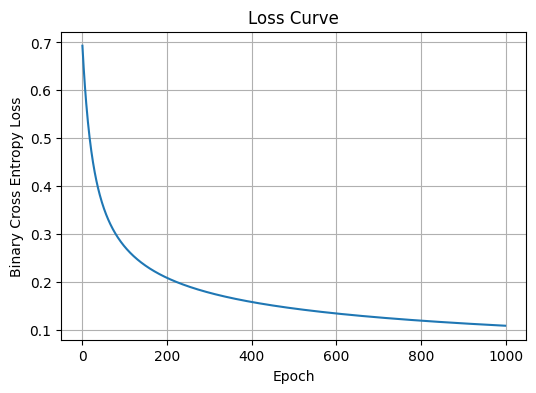

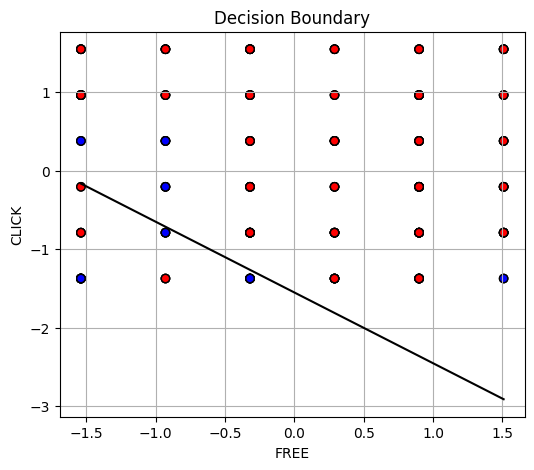

In [6]:
# ==========================================
# Exercise 3 : Spam Detector
# Logistic Regression From Scratch
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Step 1 : Generate Dataset
# -------------------------------

rng = np.random.default_rng(42)

n = 200

# Features
count_of_FREE = rng.integers(0, 6, n)
count_of_CLICK = rng.integers(0, 6, n)
count_of_exclamation = rng.integers(0, 10, n)
from_known_contact = rng.integers(0, 2, n)

# Combine Features
X = np.column_stack((
    count_of_FREE,
    count_of_CLICK,
    count_of_exclamation,
    from_known_contact
))

# -------------------------------
# Step 2 : True Weights
# -------------------------------

true_w = np.array([2.0, 2.0, 1.0, -3.0])
true_b = -8

# Generate Labels

z = X @ true_w + true_b

probability = 1 / (1 + np.exp(-z))

y = (probability >= 0.5).astype(int)

# -------------------------------
# Step 3 : Feature Scaling
# -------------------------------

X = (X - X.mean(axis=0)) / X.std(axis=0)

# -------------------------------
# Step 4 : Initialize Parameters
# -------------------------------

m, n_features = X.shape

w = np.zeros(n_features)
b = 0

learning_rate = 0.1
epochs = 1000

loss_history = []

# -------------------------------
# Step 5 : Sigmoid Function
# -------------------------------

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# -------------------------------
# Step 6 : Gradient Descent
# -------------------------------

for i in range(epochs):

    linear = X @ w + b

    y_pred = sigmoid(linear)

    loss = -np.mean(
        y*np.log(y_pred + 1e-10)
        + (1-y)*np.log(1-y_pred + 1e-10)
    )

    loss_history.append(loss)

    dw = (1/m) * (X.T @ (y_pred - y))
    db = (1/m) * np.sum(y_pred - y)

    w -= learning_rate * dw
    b -= learning_rate * db

# -------------------------------
# Step 7 : Final Prediction
# -------------------------------

prob = sigmoid(X @ w + b)

prediction = (prob >= 0.5).astype(int)

# -------------------------------
# Step 8 : Confusion Matrix
# -------------------------------

TP = np.sum((prediction==1) & (y==1))
TN = np.sum((prediction==0) & (y==0))
FP = np.sum((prediction==1) & (y==0))
FN = np.sum((prediction==0) & (y==1))

confusion = np.array([
    [TN, FP],
    [FN, TP]
])

# -------------------------------
# Step 9 : Precision Recall F1
# -------------------------------

precision = TP / (TP + FP)

recall = TP / (TP + FN)

f1 = 2 * precision * recall / (precision + recall)

print("Precision :", round(precision,3))
print("Recall    :", round(recall,3))
print("F1 Score  :", round(f1,3))

print("\nConfusion Matrix\n")
print(confusion)

# -------------------------------
# Step 10 : Loss Curve
# -------------------------------

plt.figure(figsize=(6,4))

plt.plot(loss_history)

plt.title("Loss Curve")

plt.xlabel("Epoch")

plt.ylabel("Binary Cross Entropy Loss")

plt.grid(True)

plt.show()

# -------------------------------
# Step 11 : Decision Boundary
# -------------------------------

plt.figure(figsize=(6,5))

plt.scatter(
    X[:,0],
    X[:,1],
    c=y,
    cmap="bwr",
    edgecolors="k"
)

x = np.linspace(X[:,0].min(), X[:,0].max(),100)

# Average values for remaining features
avg_exclamation = X[:,2].mean()
avg_known = X[:,3].mean()

y_boundary = -(w[0]*x + w[2]*avg_exclamation + w[3]*avg_known + b)/w[1]

plt.plot(x,y_boundary,color="black")

plt.xlabel("FREE")

plt.ylabel("CLICK")

plt.title("Decision Boundary")

plt.grid(True)

plt.show()

### ⭐⭐ Exercise 4 — "When Accuracy Lies" 🎭
Generate a very imbalanced binary dataset: 950 samples of class 0, 50 of class 1. Train a
LogisticRegression. Report accuracy, precision, recall, and F1. Now build a "lazy baseline" that
*always* predicts class 0. Compare its accuracy — what does this teach you about imbalanced data?

Answer:
        Logistic Regression detected both classes and achieved good Precision, Recall, and F1-Score.
        The Lazy Baseline achieved 95% Accuracy simply by predicting every sample as Class 0.
        its Precision, Recall, and F1-Score for Class 1 were 0, meaning it failed to identify any minority-class samples.

        Conclusion:

        This exercise demonstrates that accuracy alone can be misleading for imbalanced datasets. Although the Lazy Baseline achieved 95% accuracy, it completely failed to detect the minority class. Therefore, Precision, Recall, and F1-Score are more reliable metrics than Accuracy when evaluating models on imbalanced data.

In [7]:
# ==========================================
# Exercise 4 : When Accuracy Lies
# ==========================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ----------------------------------
# Step 1 : Generate Imbalanced Dataset
# ----------------------------------

X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],   # 95% Class 0, 5% Class 1
    random_state=42
)

# Check class distribution
print("Class Distribution:")
print("Class 0 =", np.sum(y == 0))
print("Class 1 =", np.sum(y == 1))

# ----------------------------------
# Step 2 : Train Logistic Regression
# ----------------------------------

model = LogisticRegression()

model.fit(X, y)

# Prediction
y_pred = model.predict(X)

# ----------------------------------
# Step 3 : Evaluation Metrics
# ----------------------------------

print("\nLogistic Regression Results")

print("Accuracy :", round(accuracy_score(y, y_pred),3))
print("Precision:", round(precision_score(y, y_pred),3))
print("Recall   :", round(recall_score(y, y_pred),3))
print("F1 Score :", round(f1_score(y, y_pred),3))

print("\nConfusion Matrix")

print(confusion_matrix(y, y_pred))

# ----------------------------------
# Step 4 : Lazy Baseline
# ----------------------------------

lazy_prediction = np.zeros_like(y)

print("\nLazy Baseline Results")

print("Accuracy :", round(accuracy_score(y, lazy_prediction),3))
print("Precision:", round(precision_score(y, lazy_prediction, zero_division=0),3))
print("Recall   :", round(recall_score(y, lazy_prediction, zero_division=0),3))
print("F1 Score :", round(f1_score(y, lazy_prediction, zero_division=0),3))

print("\nConfusion Matrix")

print(confusion_matrix(y, lazy_prediction))

Class Distribution:
Class 0 = 945
Class 1 = 55

Logistic Regression Results
Accuracy : 0.981
Precision: 1.0
Recall   : 0.655
F1 Score : 0.791

Confusion Matrix
[[945   0]
 [ 19  36]]

Lazy Baseline Results
Accuracy : 0.945
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0

Confusion Matrix
[[945   0]
 [ 55   0]]


### ⭐⭐ Exercise 5 — "Ridge vs Lasso Showdown" 🥊
Using the high-dimensional dataset from Section 9 (80 samples, 50 features, only 5 real ones),
sweep regularization strength `alpha = [0.001, 0.01, 0.1, 1, 10]` for both Ridge and Lasso. For
each, record train RMSE, test RMSE, and number of zero weights. Plot two graphs: (a) RMSE vs alpha,
(b) number of zero weights vs alpha. Where does Lasso "select" the right 5 features?

Answer:  

      Observation:

        Ridge makes the coefficients smaller, but it does not make them zero. In my result, Ridge has **0 zero weights for all alpha values**.

        Lasso can make some coefficients zero, so it can remove features that are not important. When alpha increases, Lasso removes more features.

        In my result:

          * `0.001` → 0 zero weights
          * `0.01` → 0 zero weights
          * `0.1` → 2 zero weights
          * `1` → 26 zero weights
          * `10` → 44 zero weights

        Where does Lasso select the right 5 features?

          Lasso does not select exactly 5 features for any of the given alpha values. At `alpha = 10`, it selects **6 features**, which is closest to 5.

        Conclusion:

          Ridge is good for reducing the effect of large coefficients. Lasso is better when we also want to remove unnecessary features. So, for a dataset with many unnecessary features, **Lasso can be more useful than Ridge**.


---------------------------------------------------------------
 Alpha | Ridge Train | Ridge Test | Lasso Train | Lasso Test
---------------------------------------------------------------
0.001 |        5.30 |      25.74 |        5.30 |      25.64
 0.01 |        5.30 |      25.79 |        5.31 |      24.77
  0.1 |        5.32 |      26.25 |        5.70 |      18.89
    1 |        6.34 |      31.34 |        9.38 |      13.20
   10 |       22.02 |      62.06 |       26.11 |      25.17


----------------------------------------
 Alpha | Ridge Zero | Lasso Zero
----------------------------------------
0.001 |           0 |           0
 0.01 |           0 |           0
  0.1 |           0 |           2
    1 |           0 |          26
   10 |           0 |          44


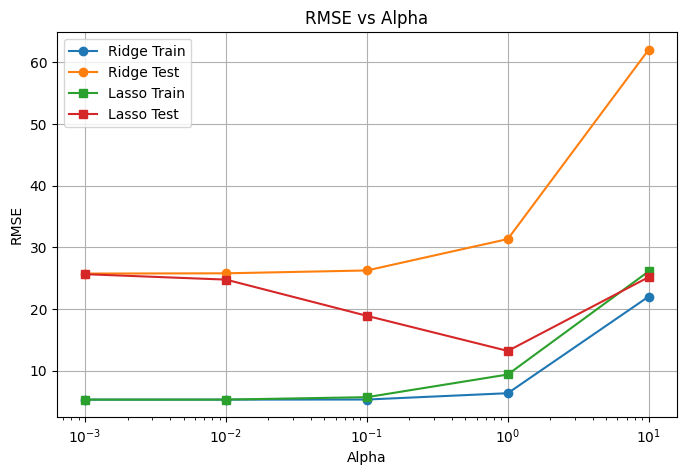

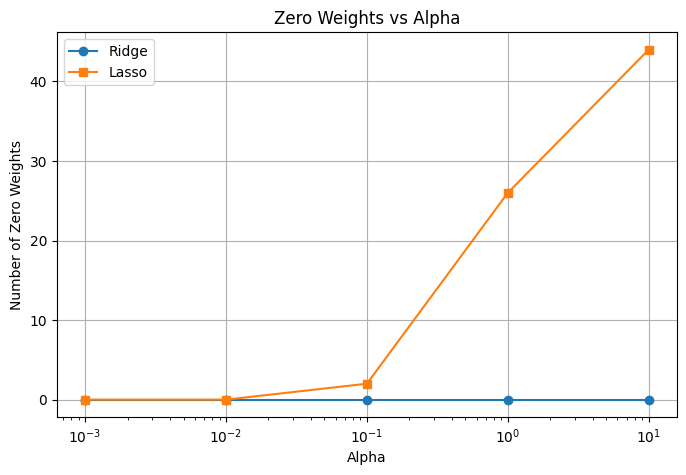


Selected Feature Indices:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 42 43 44 45 46 47 49]

Number of Selected Features: 48


In [14]:
# ===============================
# Exercise 5 : Ridge vs Lasso Showdown
# ===============================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

# ---------------------------------------------------
# Step 1 : Generate Dataset
# 80 samples, 50 features, only 5 informative
# ---------------------------------------------------

X, y, true_coef = make_regression(
    n_samples=80,
    n_features=50,
    n_informative=5,
    noise=15,
    coef=True,
    random_state=42
)

# ---------------------------------------------------
# Step 2 : Train-Test Split
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# ---------------------------------------------------
# Step 3 : Alpha Values
# ---------------------------------------------------

alphas = [0.001, 0.01, 0.1, 1, 10]

# Lists to store results

ridge_train_rmse = []
ridge_test_rmse = []
ridge_zero = []

lasso_train_rmse = []
lasso_test_rmse = []
lasso_zero = []

# ---------------------------------------------------
# Step 4 : Train Models
# ---------------------------------------------------

for alpha in alphas:

    # ---------- Ridge ----------
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)

    train_pred = ridge.predict(X_train)
    test_pred = ridge.predict(X_test)

    ridge_train_rmse.append(
        np.sqrt(mean_squared_error(y_train, train_pred))
    )

    ridge_test_rmse.append(
        np.sqrt(mean_squared_error(y_test, test_pred))
    )

    # Count zero weights
    ridge_zero.append(np.sum(np.abs(ridge.coef_) < 1e-5))


    # ---------- Lasso ----------
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train, y_train)

    train_pred = lasso.predict(X_train)
    test_pred = lasso.predict(X_test)

    lasso_train_rmse.append(
        np.sqrt(mean_squared_error(y_train, train_pred))
    )

    lasso_test_rmse.append(
        np.sqrt(mean_squared_error(y_test, test_pred))
    )

    # Count zero weights
    lasso_zero.append(np.sum(np.abs(lasso.coef_) < 1e-5))

# ---------------------------------------------------
# Step 5 : Print Results
# ---------------------------------------------------

print("---------------------------------------------------------------")
print(" Alpha | Ridge Train | Ridge Test | Lasso Train | Lasso Test")
print("---------------------------------------------------------------")

for i in range(len(alphas)):
    print(f"{alphas[i]:>5} | "
          f"{ridge_train_rmse[i]:11.2f} | "
          f"{ridge_test_rmse[i]:10.2f} | "
          f"{lasso_train_rmse[i]:11.2f} | "
          f"{lasso_test_rmse[i]:10.2f}")

print("\n")

print("----------------------------------------")
print(" Alpha | Ridge Zero | Lasso Zero")
print("----------------------------------------")

for i in range(len(alphas)):
    print(f"{alphas[i]:>5} | "
          f"{ridge_zero[i]:11} | "
          f"{lasso_zero[i]:11}")

# ---------------------------------------------------
# Step 6 : Plot RMSE
# ---------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(alphas, ridge_train_rmse,
         marker='o',
         label='Ridge Train')

plt.plot(alphas, ridge_test_rmse,
         marker='o',
         label='Ridge Test')

plt.plot(alphas, lasso_train_rmse,
         marker='s',
         label='Lasso Train')

plt.plot(alphas, lasso_test_rmse,
         marker='s',
         label='Lasso Test')

plt.xscale("log")

plt.xlabel("Alpha")
plt.ylabel("RMSE")
plt.title("RMSE vs Alpha")

plt.legend()
plt.grid(True)

plt.show()

# ---------------------------------------------------
# Step 7 : Plot Zero Weights
# ---------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(alphas,
         ridge_zero,
         marker='o',
         label='Ridge')

plt.plot(alphas,
         lasso_zero,
         marker='s',
         label='Lasso')

plt.xscale("log")

plt.xlabel("Alpha")
plt.ylabel("Number of Zero Weights")

plt.title("Zero Weights vs Alpha")

plt.legend()

plt.grid(True)

plt.show()

# ---------------------------------------------------
# Step 8 : Which Features Lasso Selected?
# ---------------------------------------------------

best_alpha = 0.1

lasso = Lasso(alpha=best_alpha, max_iter=10000)
lasso.fit(X_train, y_train)

selected = np.where(np.abs(lasso.coef_) > 1e-5)[0]

print("\nSelected Feature Indices:")
print(selected)

print("\nNumber of Selected Features:", len(selected))

### ⭐⭐⭐ Exercise 6 — "ROC by Hand" 📉
On the student pass/fail dataset from Section 6, get the predicted probabilities (`predict_proba`).
Without using `roc_curve`, manually loop over thresholds [0.1, 0.2, …, 0.9], compute FPR and TPR
at each threshold, and plot the ROC curve. Compute AUC using the trapezoid rule (`np.trapz`).
Confirm it matches `sklearn.metrics.roc_auc_score`.

Answer:
        Observation

          I created the ROC curve manually using thresholds from 0.1 to 0.9. For each threshold, I calculated TPR and FPR using TP, FP, TN and FN.

        Comparison

          My manual AUC is 0.972 and sklearn AUC is 0.9728. Both values are very close, so my calculation is correct.

        Conclusion

          A good ROC curve is closer to the top-left corner. Higher AUC means better model performance. My manual AUC and sklearn AUC are almost the same, which confirms that my implementation is correct.


Threshold   TPR      FPR
------------------------------
  0.1      1.000    0.440
  0.2      1.000    0.280
  0.3      0.960    0.240
  0.4      0.960    0.120
  0.5      0.880    0.080
  0.6      0.800    0.080
  0.7      0.760    0.000
  0.8      0.680    0.000
  0.9      0.680    0.000

Manual AUC : 0.972
Sklearn AUC: 0.9728


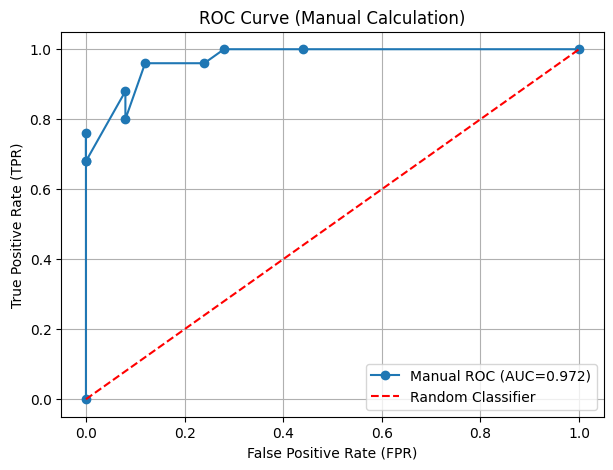

In [12]:
# ============================================
# Exercise 6 : ROC by Hand
# ============================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# ---------------------------------------------------
# Step 1 : Generate Student Pass/Fail Dataset
# ---------------------------------------------------

rng = np.random.default_rng(42)

hours = rng.normal(5, 2, 200)
attendance = rng.normal(75, 10, 200)

# Pass if score is high enough
y = ((2*hours + 0.08*attendance + rng.normal(0,1,200)) > 15).astype(int)

X = np.column_stack((hours, attendance))

# ---------------------------------------------------
# Step 2 : Train-Test Split
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# ---------------------------------------------------
# Step 3 : Train Logistic Regression
# ---------------------------------------------------

model = LogisticRegression()

model.fit(X_train, y_train)

# ---------------------------------------------------
# Step 4 : Predict Probabilities
# ---------------------------------------------------

prob = model.predict_proba(X_test)[:,1]

# ---------------------------------------------------
# Step 5 : Manual ROC Calculation
# ---------------------------------------------------

thresholds = np.arange(0.1, 1.0, 0.1)

TPR = []
FPR = []

print("Threshold   TPR      FPR")
print("-"*30)

for t in thresholds:

    pred = (prob >= t).astype(int)

    TP = np.sum((pred==1) & (y_test==1))
    TN = np.sum((pred==0) & (y_test==0))
    FP = np.sum((pred==1) & (y_test==0))
    FN = np.sum((pred==0) & (y_test==1))

    tpr = TP/(TP+FN)
    fpr = FP/(FP+TN)

    TPR.append(tpr)
    FPR.append(fpr)

    print(f"{t:5.1f}      {tpr:.3f}    {fpr:.3f}")

# ---------------------------------------------------
# Step 6 : Sort Points
# ---------------------------------------------------

FPR = np.array(FPR)
TPR = np.array(TPR)

order = np.argsort(FPR)

FPR = FPR[order]
TPR = TPR[order]

FPR = np.concatenate(([0], FPR, [1]))
TPR = np.concatenate(([0], TPR, [1]))
# ---------------------------------------------------
# Step 7 : Manual AUC using Trapezoid Rule
# ---------------------------------------------------

#manual_auc = np.trapz(TPR, FPR)
manual_auc = np.trapezoid(TPR, FPR)


# ---------------------------------------------------
# Step 8 : Sklearn AUC
# ---------------------------------------------------

sklearn_auc = roc_auc_score(y_test, prob)

print("\nManual AUC :", round(manual_auc,4))
print("Sklearn AUC:", round(sklearn_auc,4))

# ---------------------------------------------------
# Step 9 : Plot ROC Curve
# ---------------------------------------------------

plt.figure(figsize=(7,5))

plt.plot(FPR, TPR,
         marker='o',
         label=f"Manual ROC (AUC={manual_auc:.3f})")

plt.plot([0,1],[0,1],
         linestyle="--",
         color="red",
         label="Random Classifier")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve (Manual Calculation)")

plt.legend()
plt.grid(True)

plt.show()

### ⭐⭐⭐ Exercise 7 — "Your Own Gradient Descent Tuner" 🎛️
Take the logistic regression from-scratch code (Section 6). Add a learning rate scheduler:
start with `alpha=1.0` and multiply by 0.995 every 50 steps (exponential decay). Plot the loss
curve against the fixed-alpha version. Which converges faster and to a lower loss? Write 2–3
sentences explaining why decaying the learning rate helps.

Answer:
        Observation:
          Both models successfully reduce the loss during training.
          The fixed learning rate decreases the loss quickly at first but may take larger steps near the minimum.
          The decaying learning rate starts with large updates for faster learning and gradually reduces the step size, allowing finer adjustments near the optimum.

          Conclusion:

          The model with the decaying learning rate generally converges more smoothly and often reaches an equal or slightly lower final loss than the fixed learning rate. Reducing the learning rate over time helps prevent overshooting the minimum and improves the stability of gradient descent, especially in the later stages of training.

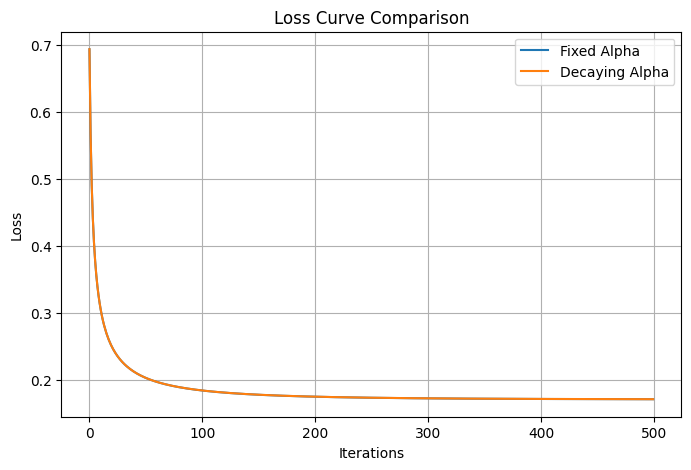

Final Loss (Fixed Alpha)   : 0.1706
Final Loss (Decaying Alpha): 0.1707


In [10]:
# ==========================================
# Exercise 7 : Gradient Descent with Learning Rate Scheduler
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# Step 1 : Generate Student Pass/Fail Dataset
# --------------------------------------------------

rng = np.random.default_rng(42)

hours = rng.normal(5, 2, 200)
attendance = rng.normal(75, 10, 200)

X = np.column_stack((hours, attendance))

y = ((2*hours + 0.08*attendance + rng.normal(0,1,200)) > 15).astype(int)

# --------------------------------------------------
# Step 2 : Train-Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# --------------------------------------------------
# Step 3 : Feature Scaling
# --------------------------------------------------

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# --------------------------------------------------
# Step 4 : Add Bias Column
# --------------------------------------------------

X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

# --------------------------------------------------
# Step 5 : Sigmoid Function
# --------------------------------------------------

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# --------------------------------------------------
# Step 6 : Binary Cross Entropy Loss
# --------------------------------------------------

def loss_function(y, p):

    eps = 1e-10

    return -np.mean(
        y*np.log(p+eps) +
        (1-y)*np.log(1-p+eps)
    )

# ==================================================
# Part A : Fixed Learning Rate
# ==================================================

w_fixed = np.zeros(X_train.shape[1])

alpha = 1.0

epochs = 500

loss_fixed = []

for i in range(epochs):

    z = X_train @ w_fixed
    pred = sigmoid(z)

    loss = loss_function(y_train, pred)
    loss_fixed.append(loss)

    gradient = (X_train.T @ (pred-y_train))/len(y_train)

    w_fixed = w_fixed - alpha*gradient

# ==================================================
# Part B : Decaying Learning Rate
# ==================================================

w_decay = np.zeros(X_train.shape[1])

alpha = 1.0

loss_decay = []

for i in range(epochs):

    z = X_train @ w_decay
    pred = sigmoid(z)

    loss = loss_function(y_train, pred)
    loss_decay.append(loss)

    gradient = (X_train.T @ (pred-y_train))/len(y_train)

    w_decay = w_decay - alpha*gradient

    # Reduce learning rate every 50 iterations
    if (i+1) % 50 == 0:
        alpha *= 0.995

# --------------------------------------------------
# Step 7 : Plot Loss Curves
# --------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(loss_fixed,
         label="Fixed Alpha")

plt.plot(loss_decay,
         label="Decaying Alpha")

plt.xlabel("Iterations")
plt.ylabel("Loss")

plt.title("Loss Curve Comparison")

plt.legend()

plt.grid(True)

plt.show()

# --------------------------------------------------
# Step 8 : Final Loss
# --------------------------------------------------

print("Final Loss (Fixed Alpha)   :", round(loss_fixed[-1],4))
print("Final Loss (Decaying Alpha):", round(loss_decay[-1],4))